Apriori algorithm for question 1

In [2]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

In [3]:
# load dữ liệu vào df
df = pd.read_csv('archive (3)/high_value_products.csv', 
                  quotechar='"', 
                  on_bad_lines='skip', 
                  engine='python')

In [4]:
df.head(10)

,order_id,product_name
0,1730387,100% Grated Parmesan Cheese
1,1730387,Natural Tomato Paste
2,1730387,Tahini
3,1730387,Mozzarella Cheese
4,1730387,Italian Bread Crumbs
5,1730387,Yukon Gold Potato
6,1730387,Cereal with Real Strawberries
7,1730387,Spicy Brown Mustard
8,1730387,Tomato Ketchup
9,1730387,Beef Franks


In [5]:
#Chuyển đổi data về dạng basket mỗi order_id là một list sản phẩm 
basket = df.groupby('order_id')['product_name'].apply(list).to_list()


In [6]:
#vì tốn quá nhiều ram khi chạy ma trận nên sẽ tiến hành lọc các sản phẩm có số lượng dưới 1% so với tổng basket.
#đếm số lượng của từng product trong một từng đơn
from collections import Counter
item_counts=Counter(
    item
    for transaction in basket
    for item in set(transaction)

)

#chọn ngưỡng min_support là 1%
min_support=0.01
min_count=min_support*len(basket)

#bắt đầu lọc qua product
filtered_basket=[[item for item in transaction if item_counts[item]>=min_count] for transaction in basket]



In [7]:
#encode về dạng ma trận
te = TransactionEncoder()
te_data = te.fit(filtered_basket).transform(filtered_basket,sparse=True)
df_encoded = pd.DataFrame.sparse.from_spmatrix(te_data, columns=te.columns_)

In [8]:
#tìm các tập sản phẩm phổ biến
frequent_itemsets=apriori(df_encoded,min_support,use_colnames=True,low_memory=True)

In [9]:
#sinh kết hợp lọc theo lift
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)
results=rules.sort_values('lift',ascending=False)

In [10]:
#kết quả sau khi chạy xong thuật toán
results

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
74,frozenset({Organic Garlic}),frozenset({Organic Yellow Onion}),0.049707,0.052345,0.010802,0.217322,4.151711,1.0,0.008200,1.210785,0.798843,0.118382,0.174090,0.211845
75,frozenset({Organic Yellow Onion}),frozenset({Organic Garlic}),0.052345,0.049707,0.010802,0.206367,4.151711,1.0,0.008200,1.197397,0.801067,0.118382,0.164855,0.211845
49,frozenset({Limes}),frozenset({Large Lemon}),0.061319,0.063705,0.012644,0.206191,3.236665,1.0,0.008737,1.179497,0.736182,0.112506,0.152181,0.202331
48,frozenset({Large Lemon}),frozenset({Limes}),0.063705,0.061319,0.012644,0.198470,3.236665,1.0,0.008737,1.171112,0.738058,0.112506,0.146110,0.202331
76,frozenset({Organic Hass Avocado}),frozenset({Organic Lemon}),0.101217,0.039371,0.010812,0.106823,2.713261,1.0,0.006827,1.075519,0.702550,0.083316,0.070217,0.190726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33,frozenset({Limes}),frozenset({Banana}),0.061319,0.193139,0.015238,0.248506,1.286667,1.0,0.003395,1.073676,0.237353,0.063700,0.068620,0.163702
36,frozenset({Banana}),frozenset({Organic Baby Spinach}),0.193139,0.101177,0.024439,0.126534,1.250630,1.0,0.004898,1.029031,0.248373,0.090555,0.028212,0.184040
37,frozenset({Organic Baby Spinach}),frozenset({Banana}),0.101177,0.193139,0.024439,0.241546,1.250630,1.0,0.004898,1.063823,0.222961,0.090555,0.059994,0.184040
40,frozenset({Organic Strawberries}),frozenset({Banana}),0.120898,0.193139,0.028071,0.232189,1.202183,1.0,0.004721,1.050858,0.191309,0.098162,0.048397,0.188765


In [11]:
sizes = results.apply(lambda r: (len(r['antecedents']), len(r['consequents'])), axis=1)
print(sizes.value_counts())

(1, 1)    88
Name: count, dtype: int64


In [12]:

# 1. chỉ giữ luật 1 sản phẩm → 1 sản phẩm
pairs_only = results[(results['antecedents'].apply(len)==1) & (results['consequents'].apply(len)==1)].copy()

# 2. tạo 2 cột phụ ngay trên pairs_only


pairs_only['cap_san_pham'] = pairs_only.apply(
    lambda r: ' + '.join(sorted([next(iter(r['antecedents'])),
                                 next(iter(r['consequents']))])), axis=1)
pairs_only['goi_y'] = pairs_only.apply(
    lambda r: f"{next(iter(r['antecedents']))} → {next(iter(r['consequents']))}", axis=1)
# 3. mỗi cặp giữ chiều confidence cao hơn, lấy 10 cặp có lift cao nhất


pairs_best=(pairs_only.sort_values('confidence',ascending=False).drop_duplicates('cap_san_pham'))
top_caps = (pairs_best.sort_values('lift', ascending=False).head(10)['cap_san_pham'])
both = (pairs_only[pairs_only['cap_san_pham'].isin(top_caps)]
        [['cap_san_pham', 'goi_y', 'consequent support', 'confidence', 'lift']]
        .sort_values(['lift', 'cap_san_pham', 'confidence'],
                     ascending=[False, True, False]))
both 


,cap_san_pham,goi_y,consequent support,confidence,lift
74,Organic Garlic + Organic Yellow Onion,Organic Garlic → Organic Yellow Onion,0.052345,0.217322,4.151711
75,Organic Garlic + Organic Yellow Onion,Organic Yellow Onion → Organic Garlic,0.049707,0.206367,4.151711
49,Large Lemon + Limes,Limes → Large Lemon,0.063705,0.206191,3.236665
48,Large Lemon + Limes,Large Lemon → Limes,0.061319,0.198470,3.236665
77,Organic Hass Avocado + Organic Lemon,Organic Lemon → Organic Hass Avocado,0.101217,0.274629,2.713261
76,Organic Hass Avocado + Organic Lemon,Organic Hass Avocado → Organic Lemon,0.039371,0.106823,2.713261
51,Large Lemon + Organic Avocado,Large Lemon → Organic Avocado,0.072138,0.179319,2.485785
50,Large Lemon + Organic Avocado,Organic Avocado → Large Lemon,0.063705,0.158356,2.485785
73,Organic Blueberries + Organic Strawberries,Organic Blueberries → Organic Strawberries,0.120898,0.276403,2.286260
72,Organic Blueberries + Organic Strawberries,Organic Strawberries → Organic Blueberries,0.038831,0.088778,2.286260


In [13]:
def chon_chieu(g):
    g = g.sort_values('confidence', ascending=False)
    best = g.iloc[0]
    if best['consequent support'] >= 0.15 and len(g) > 1:
        return g.iloc[1]
    return best

final = both.groupby('cap_san_pham').apply(chon_chieu).reset_index(drop=True)
final.sort_values('lift', ascending=False)

,goi_y,consequent support,confidence,lift
7,Organic Garlic → Organic Yellow Onion,0.052345,0.217322,4.151711
2,Limes → Large Lemon,0.063705,0.206191,3.236665
8,Organic Lemon → Organic Hass Avocado,0.101217,0.274629,2.713261
3,Large Lemon → Organic Avocado,0.072138,0.179319,2.485785
6,Organic Blueberries → Organic Strawberries,0.120898,0.276403,2.286260
4,Limes → Organic Avocado,0.072138,0.163323,2.264046
9,Organic Raspberries → Organic Strawberries,0.120898,0.273406,2.261465
0,Bag of Organic Bananas → Organic Large Extra F...,0.036252,0.079334,2.188423
1,Banana → Organic Fuji Apple,0.036864,0.079503,2.156687
5,Organic Zucchini → Organic Baby Spinach,0.101177,0.212586,2.101137


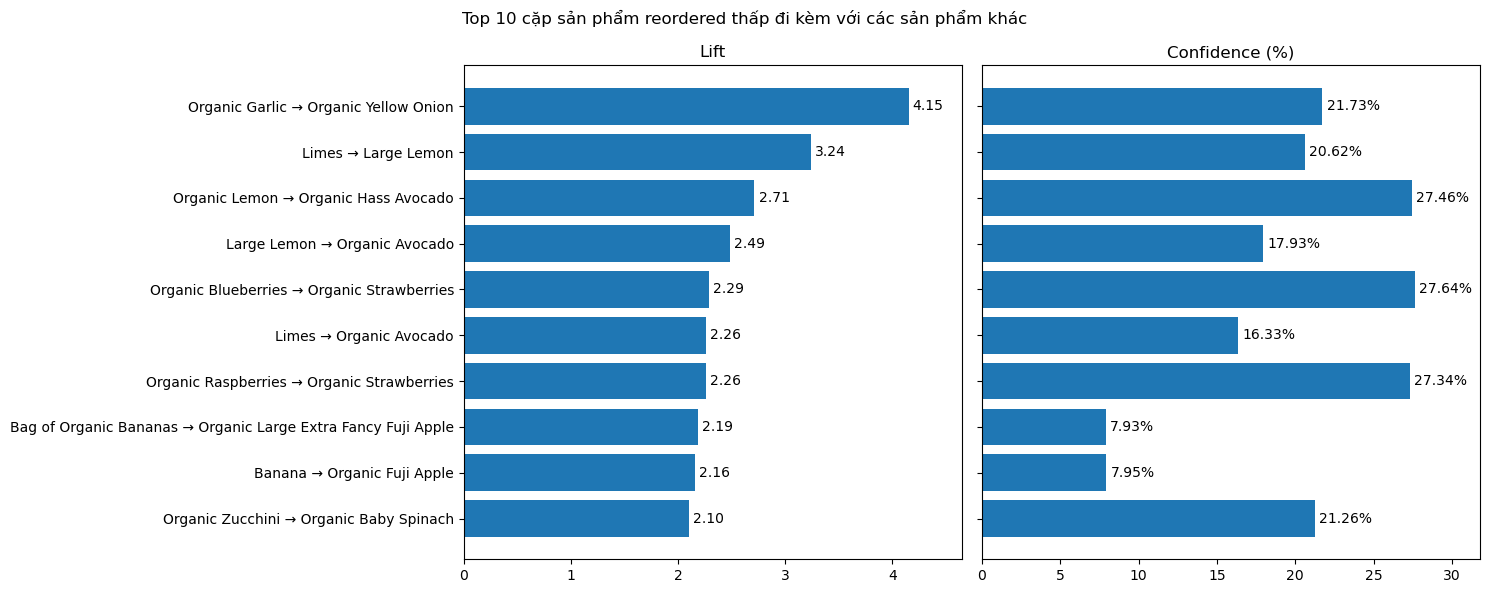

In [14]:
# Vẽ biểu đồ so sánh các cặp dựa trên kết quả
import matplotlib.pyplot as plt

top = (final.sort_values('lift', ascending=False)
                 .head(10)
                 .iloc[::-1])

fig,(ax1,ax2)= plt.subplots(1,2,figsize=(15,6),sharey=True)

ax1.barh(top['goi_y'],top['lift'])
ax1.set_title('Lift')
ax1.bar_label(ax1.containers[0],fmt='%.2f',padding=3)
ax1.margins(x=0.12)

ax2.barh(top['goi_y'],top['confidence']*100)
ax2.set_title('Confidence (%)')
ax2.bar_label(ax2.containers[0],fmt='%.2f%%',padding=3)
ax2.margins(x=0.15)
plt.suptitle('Top 10 cặp sản phẩm reordered thấp đi kèm với các sản phẩm khác')
plt.tight_layout()
plt.show()


